# Science case: stellar metallicities with the Bench

At R ~ 1800 the Bench sample configuration is LAMOST-like (LAMOST LRS is R ~ 1800 over 370 to
900 nm), so LAMOST tells us what to expect. Survey pipelines at that resolution deliver [Fe/H] to
about 0.1 dex for FGK stars once the SNR per pixel exceeds 20 to 30 (LAMOST LASP: Wu et al.
2014, Luo et al. 2015; SEGUE SSPP: about 0.11 dex for high-SNR F and G stars, Allende Prieto et
al. 2008), with a floor near 0.1 dex. About 0.05 dex is reached only by data-driven methods
trained on high-resolution labels (Ho et al. 2017; Xiang et al. 2019), and those need SNR > 50.
The ETC works per resel (2.2 pixels here), so SNR 20 per pixel is about 30 per resel. The 412 to
686 nm window contains Ca I 422.7, the G band, the Fe and Mg b lines at 516 to 519 nm and Na D at
589 nm, which is where the metallicity sensitivity comes from.

Assumptions, all of them changeable in the first code cell:

* SNR per resel targets of 30 (about 0.1 dex, LAMOST-like) and 75 (what the 0.05 dex data-driven
  methods need).
* Metric window 500 to 560 nm (the Mg b region).
* Stars as blackbodies normalised in V: 5800 K (G dwarf), 4500 K (K dwarf), 3500 K (M dwarf).
  The M dwarf is included only for the photon budget. M-dwarf metallicities at R ~ 1800 do not
  come from Mg b or Na D, and LAMOST M-dwarf [Fe/H] values are poor, so read that row as a
  throughput number and nothing more.
* Per-target overhead (slew, acquisition, read-out) of 10 min, a realistic allowance for a new pointing of the array.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis
try:
    plt.style.use('gks')      # the author's matplotlib style; skipped if you do not have it
except OSError:
    pass

In [2]:
bench = LFASTETC("bench_r1800", n_telescopes=20)
stars = {"G dwarf 5800 K": 5800, "K dwarf 4500 K": 4500, "M dwarf 3500 K": 3500}
mags = np.linspace(9, 20, 45)
window = (500, 560)
OVERHEAD = 600.0    # s per target (slew, acquisition, read-out)

## Exposure time to reach the SNR thresholds

Left panel SNR 30, right panel SNR 75. The horizontal lines mark 15 minutes and one hour. The
three curves lie almost on top of each other. That is expected: the metric window sits inside the
V band, where the magnitude pins the flux, so spectral type only enters through the slope of the
SED across the 60 nm window. Spectral type would matter if the window were far from the band in
which the magnitude is known (try I-band normalisation).

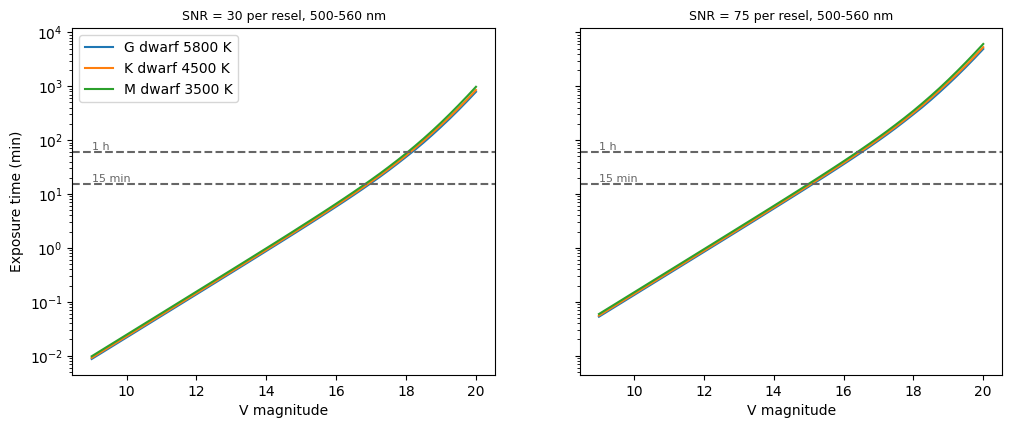

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, snr_t in zip(axes, (30, 75)):
    for label, teff in stars.items():
        t = bench.exptime_vs_mag(Source.blackbody(teff, 0, "V"), mags, snr=snr_t, wavelength=window)
        ax.plot(mags, t/60, label=label)
    ax.set_yscale('log'); ax.set_xlabel("V magnitude"); ax.set_title(f"SNR = {snr_t} per resel, 500-560 nm", fontsize=9)
    for h, txt in ((15, "15 min"), (60, "1 h")):
        ax.axhline(h, color='0.4', ls='--'); ax.text(mags[0], h*1.1, txt, fontsize=8, color='0.4')
axes[0].set_ylabel("Exposure time (min)"); axes[0].legend();

## Survey depth: limiting magnitude per exposure length

The previous section asked how long a star of a given magnitude takes; this one turns the question
around and asks how faint we can go for a fixed time budget per star. The *limiting magnitude* is the
faintest V at which the median SNR per resel over 500-560 nm reaches the target in that exposure.
It is solved analytically from the noise equation, one bin at a time, so no grid of magnitudes is
needed.

The table gives the limiting magnitude for both SNR targets (30 for ~0.1 dex, 75 for ~0.05 dex) and
all three stars, in 5, 15 and 60 minutes of on-target time. Read it as: *with this exposure, every
star brighter than this V gets a metallicity at this precision.*

In [4]:
exps = (300, 900, 3600)
depth = pd.DataFrame({(label.split()[0], f"SNR {snr_t}"): [bench.limiting_magnitude(Source.blackbody(teff, 0, "V"), t, snr_t, wavelength=window) for t in exps]
                      for label, teff in stars.items() for snr_t in (30, 75)},
                     index=pd.Index([t // 60 for t in exps], name="exposure (min)"))
depth.round(1)

G             K             M       
               SNR 30 SNR 75 SNR 30 SNR 75 SNR 30 SNR 75
exposure (min)                                          
5                15.8   13.9   15.8   13.9   15.7   13.8
15               16.9   15.1   16.9   15.0   16.8   15.0
60               18.2   16.5   18.1   16.5   18.0   16.4

With 20 telescopes a G dwarf reaches the ~0.1 dex target at V ~ 16.9 in 15 min and V ~ 18.2 in
1 h; the ~0.05 dex target stops ~1.8 mag brighter. As before, the three stars differ by at most
~0.1 mag, and only the SED matters, so the 4500 K column applies equally to K giants.

In distance (ignoring extinction), V = 16.9 and 18.2 correspond to ~2.7 and ~4.7 kpc for a G dwarf
($M_V \approx +4.8$), and V = 16.9 and 18.1 to ~19 and ~33 kpc for a K giant
($M_V \approx +0.5$): dwarfs probe the thick disc, giants reach into the halo.

How the depth grows with time tells us what limits it. Going from 5 to 15 min (x3 in time) gains ~1.1 mag
and from 15 to 60 min (x4) ~1.25 mag. That lies between the source-limited scaling
($2.5\log_{10} t$: 1.2 and 1.5 mag) and the sky-limited one ($1.25\log_{10} t$: 0.6 and 0.75 mag),
closer to the former: at these magnitudes the star's own photon noise still dominates.

## Where the information comes from: SNR across the band

The metallicity indicators are spread over the window, and the SNR per resel is far from flat
across it because the throughput and the stellar SED both change strongly between 412 and 686 nm.
The dotted lines mark the main features. For the cool stars the blue end, where Ca I and the G
band sit, is where the SNR is lowest.

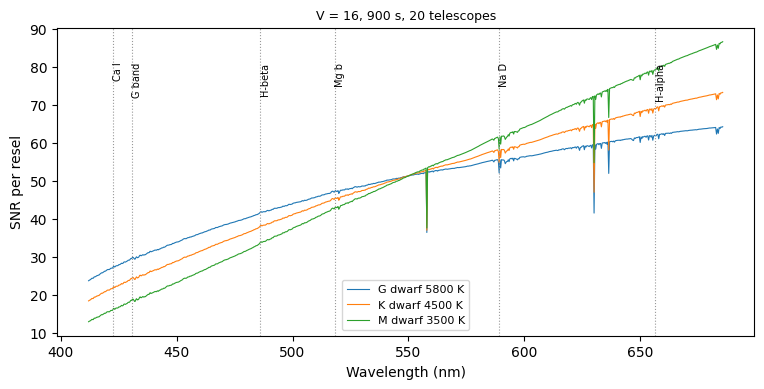

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for label, teff in stars.items():
    r = bench.snr(Source.blackbody(teff, 16, "V"), exptime=900)
    ax.plot(r.wavelength, r.snr, lw=0.8, label=label)
ymax = ax.get_ylim()[1]
for w, name in ((422.7, "Ca I"), (430.8, "G band"), (486.1, "H-beta"), (518.4, "Mg b"), (589.3, "Na D"), (656.3, "H-alpha")):
    ax.axvline(w, color='0.6', ls=':', lw=0.8); ax.text(w, ymax*0.9, name, fontsize=7, rotation=90, va='top')
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("SNR per resel"); ax.set_title("V = 16, 900 s, 20 telescopes", fontsize=9)
ax.legend(fontsize=8);

## Survey throughput

LFAST observes one star at a time, since all telescopes point at the same target. The number of
stars per night therefore follows directly from what each star costs: its exposure time plus a fixed
overhead for slewing, acquisition and read-out,

$$N_{\rm night} = \frac{8\ \mathrm{h}}{t_{\rm exp}(V) + t_{\rm overhead}}.$$

The plot shows this for G dwarfs at the ~0.1 dex target (SNR = 30 per resel), with 20 telescopes and
a 10-minute overhead. Two regimes frame the curve:

* **Bright stars** ($t_{\rm exp} \ll t_{\rm overhead}$): the overhead sets the yield, and the curve is flat.
* **Faint stars** ($t_{\rm exp} \gg t_{\rm overhead}$): the exposure sets the yield, and it falls steeply with magnitude.

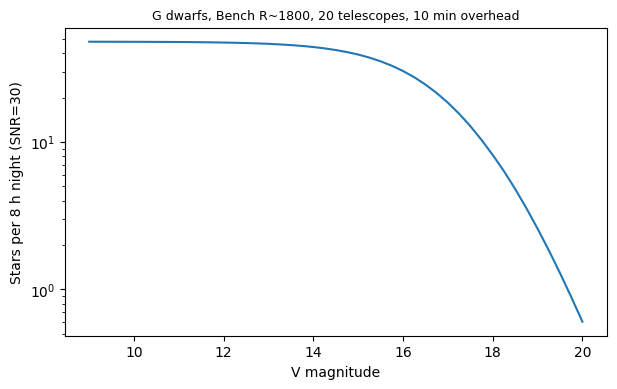

In [6]:
t = bench.exptime_vs_mag(Source.blackbody(5800, 0, "V"), mags, snr=30, wavelength=window)
n_per_night = 8*3600 / (t + OVERHEAD)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mags, n_per_night)
ax.set_yscale('log'); ax.set_xlabel("V magnitude"); ax.set_ylabel("Stars per 8 h night (SNR=30)")
ax.set_title(f"G dwarfs, Bench R~1800, 20 telescopes, {OVERHEAD/60:.0f} min overhead", fontsize=9);

Bright stars are overhead-limited: at V ~ 13 the exposure is well under a minute, so the night yields
at most 48 stars (8 h / 10 min) whatever the array size, and a bigger array buys nothing. The
exposure equals the overhead at V ~ 16.5; fainter than that the exposure dominates, and the yield
falls to ~18 per night at V = 17 and ~8 at V = 18. A larger array helps only in this faint regime,
and a faster acquisition helps most for bright targets. With one target at a time LFAST cannot compete with multiplexed surveys (LAMOST observes
~4000 stars per pointing) on numbers; its niche is depth on individually selected targets (see the
Galactic-archaeology notebook).

## Array size and survey depth at SNR 30 in 15 minutes

The 20-telescope prototype is the nominal array; 100 and 200 telescopes are two possible upgrades.
In every case the fibers from all telescopes are combined into **one** spectrograph input
(`Telescope(..., telescopes_per_input=None)`). The terms in the noise budget therefore do not all
scale with the number of telescopes N in the same way:

| term | scales with N as | why |
|---|---|---|
| source signal | $N$ | every telescope collects light from the star |
| sky | $N$ | every telescope has its own fiber, and each fiber sees its own patch of sky: 20 fibers bring 20x the sky of one |
| read noise, dark current | 1 | there is one spectrograph, read out once |

Going from 20 to N telescopes multiplies the signal and the sky by N/20 and leaves the detector terms
unchanged. How much depth that buys depends on which term dominates the noise:

* source-dominated: $\Delta m = 2.5\log_{10}(N/20)$, i.e. 1.75 mag for 100 telescopes and 2.5 mag for 200;
* sky-dominated: half that, $1.25\log_{10}(N/20)$, because the sky noise grows along with the signal;
* detector-dominated: the full $2.5\log_{10}(N/20)$ again, because the read noise does not grow at all.

In [7]:
rows = {}
for n in (20, 100, 200):
    e = LFASTETC("bench_r1800", telescope=Telescope(n_telescopes=n, telescopes_per_input=None))
    rows[n] = {"D_eq (m)": e.telescope.equivalent_diameter_m,
               "V_lim (SNR=30, 15 min)": e.limiting_magnitude(Source.blackbody(5800, 0, 'V'), 900, 30, wavelength=window)}
trade = pd.DataFrame(rows).T.rename_axis("N telescopes")
trade["gain vs N=20 (mag)"] = trade["V_lim (SNR=30, 15 min)"] - trade.loc[20, "V_lim (SNR=30, 15 min)"]
trade.round(2)

,D_eq (m),"V_lim (SNR=30, 15 min)",gain vs N=20 (mag)
N telescopes,,,
20,3.25,16.94,0.00
100,7.26,18.36,1.42
200,10.27,18.88,1.95


The gain (+1.4 mag for 100 telescopes, +2.0 for 200) sits between the two limits. At the
200-telescope limit (V ~ 18.9) the star and the sky each contribute ~1800 e$^-$ per resel in 15 min,
while the detector adds only ~30 e$^{-2}$ of variance, so for the Bench the detector noise hardly matters
either way: feeding each 20-telescope array into its own input instead would cost only ~0.05 mag
here. It matters much more for CSHELL, whose read noise is 6x higher.

Caveat: merging 100-200 telescopes into one spectrograph input needs a larger output fiber or a
second combiner stage. A larger fiber image covers more detector pixels per resel, which raises the
detector noise; the ETC keeps the pixels per resel fixed, so these numbers are an upper limit on the
gain.

## Things to try

* Move the metric window to the G band (425 to 435 nm) and compare the depth. This is the window
  that matters for carbon-enhanced metal-poor stars.
* Switch to the `bench_1200_28p7_o2` preset (R ~ 3700 around 400 nm). Does the higher resolution
  pay for itself in exposure time at fixed SNR per resel?